**The program for calculation of the electric field using method of moments. S.A.Spirin et al. Three-dimensional three-photon Stark spectroscopy of single Rydberg Rb atoms in an ultrahigh-vacuum glass cell with eight electrodes**

In [ ]:
import numpy as np

# ----------------------------------------------------------------------
# Physical constants and geometry
# ----------------------------------------------------------------------
EPS0 = 8.8541878128e-12          # vacuum permittivity [F/m]

Rin  = 25e-3                     # inner radius [m]
Rout = 35e-3                     # outer radius [m]
d    = 35e-3                     # distance between the two rings [m]



# Voltages on the 4 quadrants of each ring
V_ring1 = [0.0, 10.0, 10.0, 0.0]   # ring at z = 0
V_ring2 = [0.0, 10.0, 10.0, 0.0]   # ring at z = d

# Discretization resolution of one full annulus
Nr   = 8                         # radial subdivisions
Nphi = 48                        # angular subdivisions over full 360 deg (must be /4)

# ----------------------------------------------------------------------
# Build the patches (centers, areas, potentials)
# ----------------------------------------------------------------------
def build_patches():
    centers = []     # patch center coordinates (x, y, z)
    areas   = []     # patch areas
    volts   = []     # prescribed potential of the patch's electrode
    seg_id  = []     # which of the 8 electrodes the patch belongs to

    r_edges   = np.linspace(Rin, Rout, Nr + 1)
    phi_edges = np.linspace(0.0, 2*np.pi, Nphi + 1)

    rings = [(0.0, V_ring1), (d, V_ring2)]

    for ring_index, (z, Vquad) in enumerate(rings):
        for ip in range(Nphi):
            phi0, phi1 = phi_edges[ip], phi_edges[ip + 1]
            phic = 0.5 * (phi0 + phi1)
            dphi = phi1 - phi0
            # which quadrant (0..3) -> which voltage
            quad = int(phic // (np.pi / 2)) % 4
            V = Vquad[quad]
            electrode = ring_index * 4 + quad
            for ir in range(Nr):
                r0, r1 = r_edges[ir], r_edges[ir + 1]
                rc = 0.5 * (r0 + r1)
                dr = r1 - r0
                area = rc * dr * dphi                      # dA = r dr dphi
                x = rc * np.cos(phic)
                y = rc * np.sin(phic)
                centers.append((x, y, z))
                areas.append(area)
                volts.append(V)
                seg_id.append(electrode)

    return (np.array(centers), np.array(areas),
            np.array(volts),   np.array(seg_id))


# ----------------------------------------------------------------------
# Assemble and solve the Method-of-Moments system  P sigma = V
# ----------------------------------------------------------------------
def solve_charges(centers, areas, volts):
    N = len(areas)
    P = np.zeros((N, N))

    for j in range(N):
        rj = centers[j]
        dv = centers - rj                     # vectors from all patches to patch j
        dist = np.sqrt(np.sum(dv**2, axis=1))

        # off-diagonal: point-charge (monopole) approximation of each patch
        with np.errstate(divide='ignore'):
            P[j, :] = areas / (4.0 * np.pi * EPS0 * dist)

        # diagonal (self term): potential at center of a uniformly charged
        # disk of equal area, radius a = sqrt(A/pi) ->  V = sigma * a / (2 eps0)
        a_eq = np.sqrt(areas[j] / np.pi)
        P[j, j] = a_eq / (2.0 * EPS0)

    sigma = np.linalg.solve(P, volts)         # surface charge densities [C/m^2]
    return sigma


# ----------------------------------------------------------------------
# Potential and electric field of the charged patches at arbitrary points
# ----------------------------------------------------------------------
def potential_at(points, centers, areas, sigma):
    """Electric potential [V] at an array of points (M,3)."""
    q = sigma * areas                          # charge of each patch
    pts = np.atleast_2d(points)
    V = np.zeros(len(pts))
    for i, p in enumerate(pts):
        dv = p - centers
        dist = np.sqrt(np.sum(dv**2, axis=1))
        dist[dist < 1e-12] = 1e-12
        V[i] = np.sum(q / (4.0 * np.pi * EPS0 * dist))
    return V


def field_at(points, centers, areas, sigma):
    """Electric field vector [V/m] at an array of points (M,3)."""
    q = sigma * areas
    pts = np.atleast_2d(points)
    E = np.zeros((len(pts), 3))
    for i, p in enumerate(pts):
        dv = p - centers                       # (N,3)
        dist = np.sqrt(np.sum(dv**2, axis=1))
        dist[dist < 1e-12] = 1e-12
        coeff = q / (4.0 * np.pi * EPS0 * dist**3)
        E[i] = np.sum(coeff[:, None] * dv, axis=0)
    return E


# ----------------------------------------------------------------------
# Main
# ----------------------------------------------------------------------
if __name__ == "__main__":
    centers, areas, volts, seg_id = build_patches()
    print(f"Number of patches: {len(areas)}")

    sigma = solve_charges(centers, areas, volts)

    # --- check: recovered potentials on each electrode ---
    Vcheck = potential_at(centers, centers, areas, sigma)  # slow but fine for a check
    print("\nElectrode  set V   mean recovered V")
    for e in range(8):
        m = seg_id == e
        print(f"   {e:2d}     {volts[m][0]:4.1f}      {Vcheck[m].mean():8.4f}")

    # --- evaluate the field at some sample points ---
    zc = d / 2.0
    samples = np.array([
        [0.0,      0.0,      zc],     # on the axis, midway between rings
        [Rin,      0.0,      zc],     # inner edge, midway
        [0.030,    0.0,      zc],     # inside the gap
        [0.0,      0.030,    zc],
    ])
    Es = field_at(samples, centers, areas, sigma)
    Vs = potential_at(samples, centers, areas, sigma)

    print("\nSample point (mm)            V [volt]      |E| [V/m]      E vector [V/m]")
    for p, V, E in zip(samples, Vs, Es):
        print(f"({p[0]*1e3:6.1f},{p[1]*1e3:6.1f},{p[2]*1e3:6.1f})  "
              f"{V:9.4f}   {np.linalg.norm(E):10.2f}   "
              f"[{E[0]:9.2f} {E[1]:9.2f} {E[2]:9.2f}]")

    # ------------------------------------------------------------------
    # Optional: plot the potential map in the mid-plane z = d/2
    # ------------------------------------------------------------------
    try:
        import matplotlib.pyplot as plt
        plt.rcParams.update({'font.size': 16}) 
        n = 60
        span = Rout * 1.2
        xs = np.linspace(-span, span, n)
        ys = np.linspace(-span, span, n)
        X, Y = np.meshgrid(xs, ys)
        grid = np.column_stack([X.ravel(), Y.ravel(),
                                np.full(X.size, zc)])
        Vgrid = potential_at(grid, centers, areas, sigma).reshape(X.shape)
        Egrid = field_at(grid, centers, areas, sigma)
        Ex = Egrid[:, 0].reshape(X.shape)
        Ey = Egrid[:, 1].reshape(X.shape)

        plt.figure(figsize=(7, 6))
        cf = plt.contourf(X*1e3, Y*1e3, Vgrid, 40, cmap="RdBu_r")
        plt.colorbar(cf, label="Potential [V]")
        plt.streamplot(X*1e3, Y*1e3, Ex, Ey, color="k",
                       density=1.2, linewidth=0.6)
        plt.title(f"Potential and E-field in the mid-plane")
        plt.xlabel("x [mm]");  plt.ylabel("y [mm]")
        plt.gca().set_aspect("equal")
        plt.tight_layout()
        plt.savefig('Potential.svg', format='svg')
        plt.show()
    except ImportError:
        print("\n(matplotlib not available – skipping the plot)")

Solved 768 patches. Rendering visualizations...


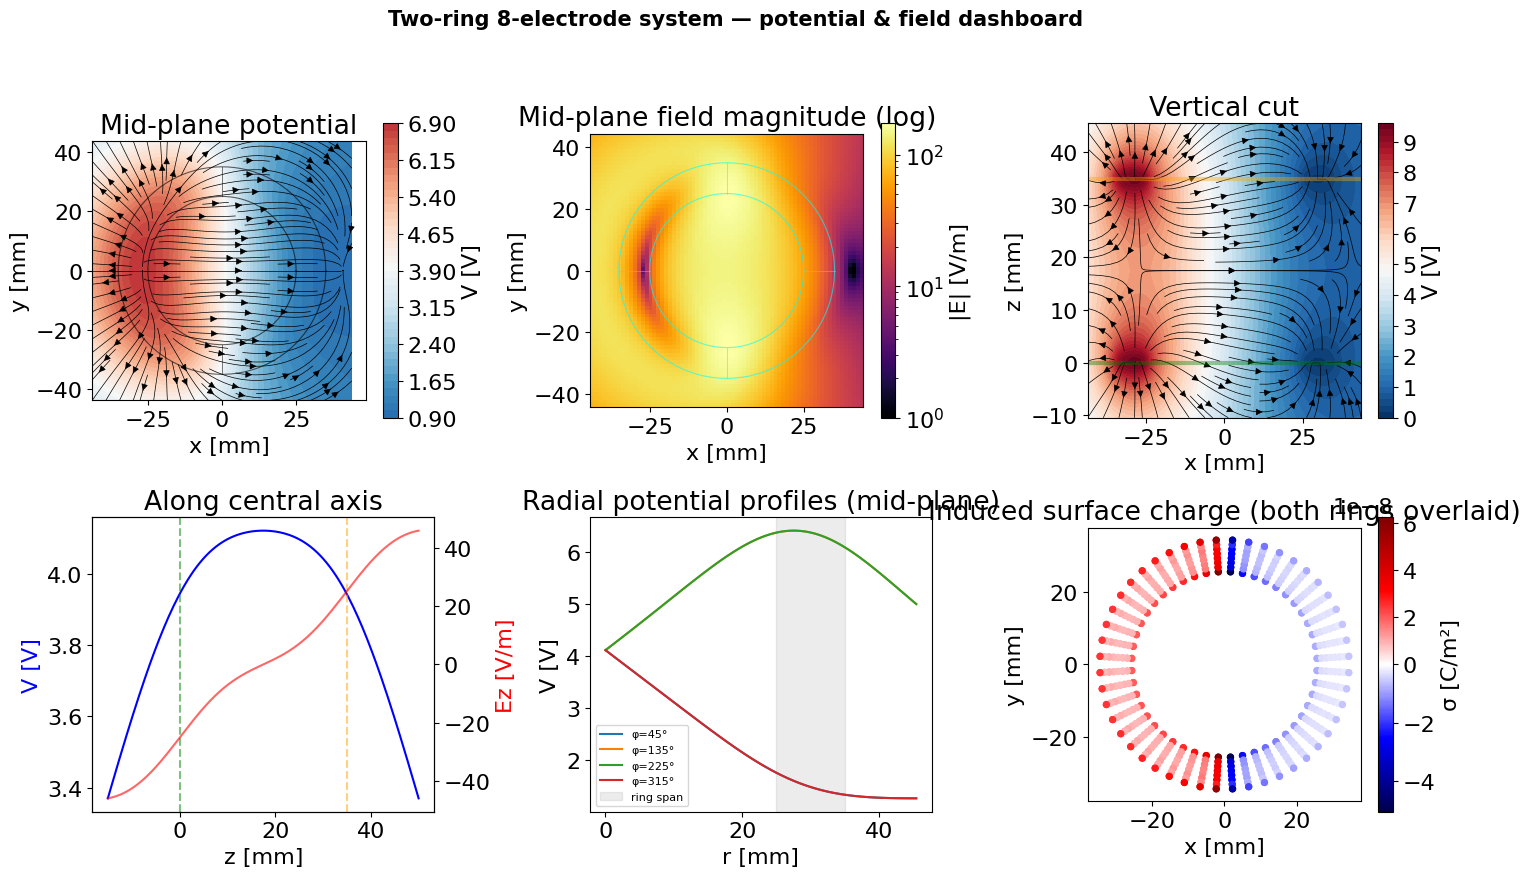

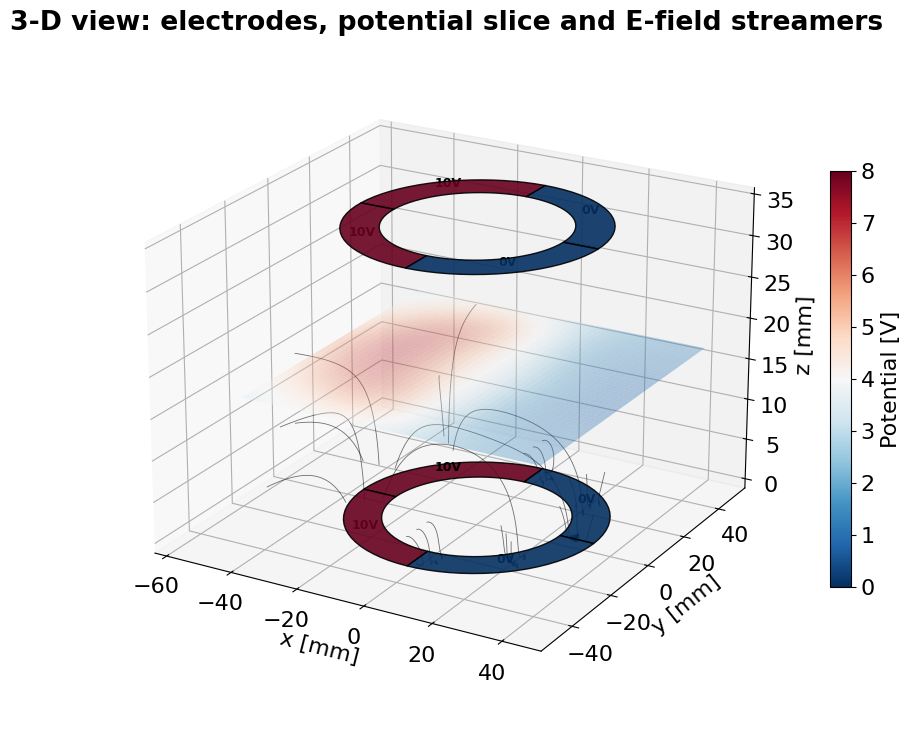

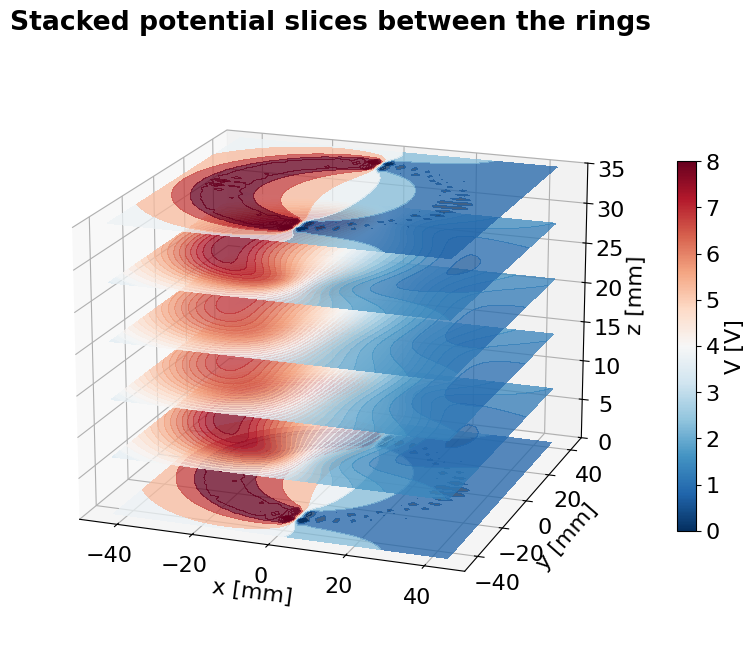

In [9]:
import matplotlib.pyplot as plt
from matplotlib import cm, colors
from mpl_toolkits.mplot3d.art3d import Poly3DCollection


# ----------------------------------------------------------------------
# Helper: sample V and E on a rectangular grid in an arbitrary plane
# ----------------------------------------------------------------------
def sample_plane(centers, areas, sigma, plane="z", coord=None,
                 span=None, n=70):
    """Return meshgrid (A, B) and fields on a plane.
       plane 'z' -> XY at height coord; 'x' -> YZ; 'y' -> XZ."""
    if span is None:
        span = Rout * 1.25
    u = np.linspace(-span, span, n)
    if plane == "z":
        A, B = np.meshgrid(u, u)
        z = coord if coord is not None else d / 2
        pts = np.column_stack([A.ravel(), B.ravel(), np.full(A.size, z)])
        e_idx = (0, 1)                        # in-plane field comps
    elif plane == "y":                        # XZ plane
        u2 = np.linspace(-0.3*d, d + 0.3*d, n)
        A, B = np.meshgrid(u, u2)
        y = coord if coord is not None else 0.0
        pts = np.column_stack([A.ravel(), np.full(A.size, y), B.ravel()])
        e_idx = (0, 2)
    else:                                     # 'x' -> YZ plane
        u2 = np.linspace(-0.3*d, d + 0.3*d, n)
        A, B = np.meshgrid(u, u2)
        x = coord if coord is not None else 0.0
        pts = np.column_stack([np.full(A.size, x), A.ravel(), B.ravel()])
        e_idx = (1, 2)

    V = potential_at(pts, centers, areas, sigma).reshape(A.shape)
    E = field_at(pts, centers, areas, sigma)
    Ea = E[:, e_idx[0]].reshape(A.shape)
    Eb = E[:, e_idx[1]].reshape(A.shape)
    Emag = np.sqrt(np.sum(E**2, axis=1)).reshape(A.shape)
    return A, B, V, Ea, Eb, Emag


# ----------------------------------------------------------------------
# Geometry of the electrode segments (for drawing them)
# ----------------------------------------------------------------------
def electrode_polygons():
    """Return list of (vertices, voltage, quadrant, ring) for the 8 pads."""
    polys = []
    rings = [(0.0, [V_ring1[0], V_ring1[1], V_ring1[2], V_ring1[3]]), (d, [V_ring2[0], V_ring2[1], V_ring2[2], V_ring2[3]])]
    for z, Vq in rings:
        for q in range(4):
            a0, a1 = q * np.pi / 2, (q + 1) * np.pi / 2
            ang = np.linspace(a0, a1, 20)
            outer = np.column_stack([Rout*np.cos(ang), Rout*np.sin(ang),
                                     np.full_like(ang, z)])
            inner = np.column_stack([Rin*np.cos(ang[::-1]), Rin*np.sin(ang[::-1]),
                                     np.full_like(ang, z)])
            verts = np.vstack([outer, inner])
            polys.append((verts, Vq[q], q, z))
    return polys


# ======================================================================
#  FIGURE 1 — Multi-panel 2D dashboard
# ======================================================================
def dashboard(centers, areas, sigma):
    zc = d / 2
    fig = plt.figure(figsize=(15, 9))
    fig.suptitle("Two-ring 8-electrode system — potential & field dashboard",
                 fontsize=15, weight="bold")

    # global voltage range for consistent colormaps
    vmin, vmax = 0, 8

    # --- Panel A: mid-plane potential + streamlines ---
    ax = fig.add_subplot(2, 3, 1)
    A, B, V, Ea, Eb, Em = sample_plane(centers, areas, sigma, "z", zc)
    cf = ax.contourf(A*1e3, B*1e3, V, 50, cmap="RdBu_r", vmin=vmin, vmax=vmax)
    ax.streamplot(A*1e3, B*1e3, Ea, Eb, color="k", density=1.3, linewidth=0.5)
    _ring_outline(ax)
    plt.colorbar(cf, ax=ax, label="V [V]")
    ax.set_title(f"Mid-plane potential")
    ax.set_aspect("equal"); ax.set_xlabel("x [mm]"); ax.set_ylabel("y [mm]")

    # --- Panel B: mid-plane field magnitude (log glow) ---
    ax = fig.add_subplot(2, 3, 2)
    lg = ax.pcolormesh(A*1e3, B*1e3, Em, cmap="inferno",
                       norm=colors.LogNorm(vmin=max(Em.min(),1),
                                           vmax=Em.max()), shading="auto")
    _ring_outline(ax, c="cyan")
    plt.colorbar(lg, ax=ax, label="|E| [V/m]")
    ax.set_title("Mid-plane field magnitude (log)")
    ax.set_aspect("equal"); ax.set_xlabel("x [mm]"); ax.set_ylabel("y [mm]")

    # --- Panel C: vertical cut (x-z plane, y=0) potential+field ---
    ax = fig.add_subplot(2, 3, 3)
    A2, B2, V2, Ea2, Eb2, Em2 = sample_plane(centers, areas, sigma, "y", 0.0)
    cf = ax.contourf(A2*1e3, B2*1e3, V2, 50, cmap="RdBu_r")
    ax.streamplot(A2*1e3, B2*1e3, Ea2, Eb2, color="k",
                  density=1.2, linewidth=0.5)
    ax.axhline(0, color="green", lw=3, alpha=.4)
    ax.axhline(d*1e3, color="orange", lw=3, alpha=.4)
    plt.colorbar(cf, ax=ax, label="V [V]")
    ax.set_title("Vertical cut")
    ax.set_xlabel("x [mm]"); ax.set_ylabel("z [mm]")

    # --- Panel D: potential along the central axis ---
    ax = fig.add_subplot(2, 3, 4)
    zz = np.linspace(-15e-3, d + 15e-3, 200)
    axis_pts = np.column_stack([np.zeros_like(zz), np.zeros_like(zz), zz])
    Vax = potential_at(axis_pts, centers, areas, sigma)
    Eax = field_at(axis_pts, centers, areas, sigma)[:, 2]
    ax.plot(zz*1e3, Vax, "b-", label="V [V]")
    ax.axvline(0, color="green", ls="--", alpha=.5)
    ax.axvline(d*1e3, color="orange", ls="--", alpha=.5)
    ax.set_xlabel("z [mm]"); ax.set_ylabel("V [V]", color="b")
    ax2 = ax.twinx()
    ax2.plot(zz*1e3, Eax, "r-", alpha=.6, label="Ez")
    ax2.set_ylabel("Ez [V/m]", color="r")
    ax.set_title("Along central axis")

    # --- Panel E: radial profile in mid-plane (averaged over angle) ---
    ax = fig.add_subplot(2, 3, 5)
    rr = np.linspace(0, Rout*1.3, 120)
    for phi_deg, lab in [(45, "quad0"), (135, "quad1"),
                         (225, "quad2"), (315, "quad3")]:
        phi = np.radians(phi_deg)
        p = np.column_stack([rr*np.cos(phi), rr*np.sin(phi),
                             np.full_like(rr, zc)])
        Vr = potential_at(p, centers, areas, sigma)
        ax.plot(rr*1e3, Vr, label=f"φ={phi_deg}°")
    ax.axvspan(Rin*1e3, Rout*1e3, color="grey", alpha=.15, label="ring span")
    ax.set_xlabel("r [mm]"); ax.set_ylabel("V [V]")
    ax.set_title("Radial potential profiles (mid-plane)")
    ax.legend(fontsize=8)

    # --- Panel F: surface-charge density on the electrodes ---
    ax = fig.add_subplot(2, 3, 6)
    sc = ax.scatter(centers[:, 0]*1e3, centers[:, 1]*1e3,
                    c=sigma, cmap="seismic", s=18,
                    norm=colors.TwoSlopeNorm(vcenter=0))
    plt.colorbar(sc, ax=ax, label="σ [C/m²]")
    ax.set_title("Induced surface charge (both rings overlaid)")
    ax.set_aspect("equal"); ax.set_xlabel("x [mm]"); ax.set_ylabel("y [mm]")

    fig.tight_layout(rect=[0, 0, 1, 0.96])
    plt.savefig('Image1.svg', format='svg')
    return fig


def _ring_outline(ax, c="k"):
    ang = np.linspace(0, 2*np.pi, 200)
    for R in (Rin, Rout):
        ax.plot(R*np.cos(ang)*1e3, R*np.sin(ang)*1e3, c, lw=0.8, alpha=.6)
    for k in range(4):                        # quadrant separators
        a = k*np.pi/2
        ax.plot([Rin*np.cos(a)*1e3, Rout*np.cos(a)*1e3],
                [Rin*np.sin(a)*1e3, Rout*np.sin(a)*1e3], c, lw=0.6, alpha=.6)


# ======================================================================
#  FIGURE 2 — 3D scene: electrodes + field streamers + slice
# ======================================================================
def scene_3d(centers, areas, sigma):
    fig = plt.figure(figsize=(11, 9))
    ax = fig.add_subplot(111, projection="3d")
    ax.set_title("3-D view: electrodes, potential slice and E-field streamers",
                 weight="bold")

    # --- draw the 8 electrode pads colored by their voltage ---
    norm = colors.Normalize(0, 8)
    cmap = cm.RdBu_r
    for verts, V, q, z in electrode_polygons():
        pc = Poly3DCollection([verts*1e3], alpha=0.9)
        pc.set_facecolor(cmap(norm(V)))
        pc.set_edgecolor("k")
        ax.add_collection3d(pc)
        # label
        a = (q + 0.5) * np.pi / 2
        rm = (Rin + Rout) / 2
        ax.text(rm*np.cos(a)*1e3, rm*np.sin(a)*1e3, z*1e3,
                f"{V:g}V", color="k", fontsize=9, ha="center", weight="bold")

    # --- translucent potential slice in the mid-plane ---
    A, B, V, _, _, _ = sample_plane(centers, areas, sigma, "z", d/2, n=50)
    Z = np.full_like(A, d/2)
    facec = cmap(norm(V))
    ax.plot_surface(A*1e3, B*1e3, Z*1e3, facecolors=facec,
                    rstride=1, cstride=1, alpha=0.35,
                    linewidth=0, antialiased=True, shade=False)

    # --- 3D field "streamers": integrate E-field lines from seed points ---
    seeds = []
    for r in np.linspace(Rin, Rout, 3):
        for phi in np.linspace(0, 2*np.pi, 8, endpoint=False):
            seeds.append([r*np.cos(phi), r*np.sin(phi), 0.1*d])
    for s in seeds:
        line = trace_fieldline(np.array(s), centers, areas, sigma,
                               step=0.6e-3, nmax=400)
        if len(line) > 3:
            ax.plot(line[:, 0]*1e3, line[:, 1]*1e3, line[:, 2]*1e3,
                    color="k", lw=0.6, alpha=0.55)

    m = cm.ScalarMappable(norm=norm, cmap=cmap)
    m.set_array([])
    fig.colorbar(m, ax=ax, shrink=0.6, label="Potential [V]")
    ax.set_xlabel("x [mm]"); ax.set_ylabel("y [mm]"); ax.set_zlabel("z [mm]")
    ax.view_init(elev=22, azim=-60)
    plt.savefig('Image2.svg', format='svg')
    return fig


def trace_fieldline(p, centers, areas, sigma, step=1e-3, nmax=300):
    """Trace an electric field line starting at p (meters)."""
    pts = [p.copy()]
    zmin, zmax = -0.3*d, d + 0.3*d
    for _ in range(nmax):
        E = field_at(p, centers, areas, sigma)[0]
        n = np.linalg.norm(E)
        if n < 1e-9:
            break
        p = p + step * E / n                 # follow the field direction
        pts.append(p.copy())
        # stop if we leave the region or hit an electrode plane far out
        r = np.hypot(p[0], p[1])
        if not (zmin < p[2] < zmax) or r > Rout*1.6:
            break
    return np.array(pts)


# ======================================================================
#  FIGURE 3 — stacked cross-section "CT scan" of the potential
# ======================================================================
def stacked_slices(centers, areas, sigma):
    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection="3d")
    ax.set_title("Stacked potential slices between the rings", weight="bold")
    norm = colors.Normalize(0, 8)
    for z in np.linspace(0, d, 6):
        A, B, V, _, _, _ = sample_plane(centers, areas, sigma, "z", z, n=45)
        ax.contourf(A*1e3, B*1e3, V, 30, zdir="z", offset=z*1e3,
                    cmap="RdBu_r", norm=norm, alpha=0.75)
    ax.set_zlim(0, d*1e3)
    ax.set_xlabel("x [mm]"); ax.set_ylabel("y [mm]"); ax.set_zlabel("z [mm]")
    m = cm.ScalarMappable(norm=norm, cmap="RdBu_r"); m.set_array([])
    fig.colorbar(m, ax=ax, shrink=0.6, label="V [V]")
    ax.view_init(elev=18, azim=-70)
    plt.savefig('Image3.svg', format='svg')
    return fig


# ----------------------------------------------------------------------
if __name__ == "__main__":
    centers, areas, volts, seg_id = build_patches()
    sigma = solve_charges(centers, areas, volts)
    print(f"Solved {len(areas)} patches. Rendering visualizations...")

    dashboard(centers, areas, sigma)
    scene_3d(centers, areas, sigma)
    stacked_slices(centers, areas, sigma)
    plt.show()

In [3]:
# ----------------------------------------------------------------------
# Convenience wrapper: field & potential at one or many arbitrary points
# ----------------------------------------------------------------------
def EV(points_mm, centers, areas, sigma):
    """
    Electric field and potential at arbitrary point(s).

    Parameters
    ----------
    points_mm : sequence
        A single point [x, y, z] or a list/array of points, in MILLIMETERS.

    Returns
    -------
    result : list of dicts with keys:
        'point_mm' : the point in mm
        'V'        : potential [V]
        'E'        : field vector [V/m]  (Ex, Ey, Ez)
        'Emag'     : |E| [V/m]
    """
    pts_mm = np.atleast_2d(np.asarray(points_mm, dtype=float))
    pts_m  = pts_mm * 1e-3                       # mm -> m

    V = potential_at(pts_m, centers, areas, sigma)
    E = field_at(pts_m,     centers, areas, sigma)

    out = []
    for p_mm, v, e in zip(pts_mm, V, E):
        out.append({
            'point_mm': p_mm,
            'V':        v,
            'E':        e,
            'Emag':     float(np.linalg.norm(e)),
        })
    return out


def print_EV(results):
    """Pretty-print the output of EV()."""
    print("\n  x[mm]    y[mm]    z[mm]     V[V]        Ex[V/m]     "
          "Ey[V/m]     Ez[V/m]     |E|[V/m]")
    print("  " + "-" * 86)
    for r in results:
        x, y, z = r['point_mm']
        ex, ey, ez = r['E']
        print(f"  {x:7.2f} {y:7.2f} {z:7.2f}  {r['V']:9.4f}  "
              f"{ex:10.2f} {ey:10.2f} {ez:10.2f}  {r['Emag']:11.2f}")


# ----------------------------------------------------------------------
# Interactive session
# ----------------------------------------------------------------------
if __name__ == "__main__":
    # --- rebuild geometry and solve for the charge distribution once ---
    centers, areas, volts, seg_id = build_patches()
    sigma = solve_charges(centers, areas, volts)
    print(f"Solved charge distribution on {len(areas)} patches.\n")

    # --- Example 1: a hand-picked list of arbitrary points ------------
    arbitrary_points_mm = [
        [ 0,  0, 17.5],     # on axis, mid-plane
        [10,  5, 20  ],     # somewhere inside the gap
        [30, 30, 10  ],     # off to the side
        [ 0, 30, 35  ],     # in the plane of ring 2
        [-15, 20, 5  ],
    ]
    print("Field at a predefined list of arbitrary points:")
    print_EV(EV(arbitrary_points_mm, centers, areas, sigma))

    # --- Example 2: type your own coordinates at runtime --------------
    print("\nEnter arbitrary points as:  x y z   (in mm).  Blank line to quit.")
    while True:
        try:
            line = input("point > ").strip()
        except (EOFError, KeyboardInterrupt):
            break
        if not line:
            
            break
        try:
            x, y, z = (float(v) for v in line.replace(",", " ").split())
        except ValueError:
            print("  Please enter three numbers, e.g.  12 -4 20")
            continue
        print_EV(EV([x, y, z], centers, areas, sigma))

Solved charge distribution on 768 patches.

Field at a predefined list of arbitrary points:

  x[mm]    y[mm]    z[mm]     V[V]        Ex[V/m]     Ey[V/m]     Ez[V/m]     |E|[V/m]
  --------------------------------------------------------------------------------------
     0.00    0.00   17.50     4.1204        0.00     142.78       0.00       142.78
    10.00    5.00   20.00     3.3888        5.29     145.23       3.96       145.38
    30.00   30.00   10.00     1.2109      -22.39      11.71     -15.03        29.40
     0.00   30.00   35.00     0.1573       -0.00      -2.35      -4.71         5.26
   -15.00   20.00    5.00     1.0539      -38.66      95.05     -96.47       140.84

Enter arbitrary points as:  x y z   (in mm).  Blank line to quit.


point >  


Solved 768 patches. Building field-component figure...


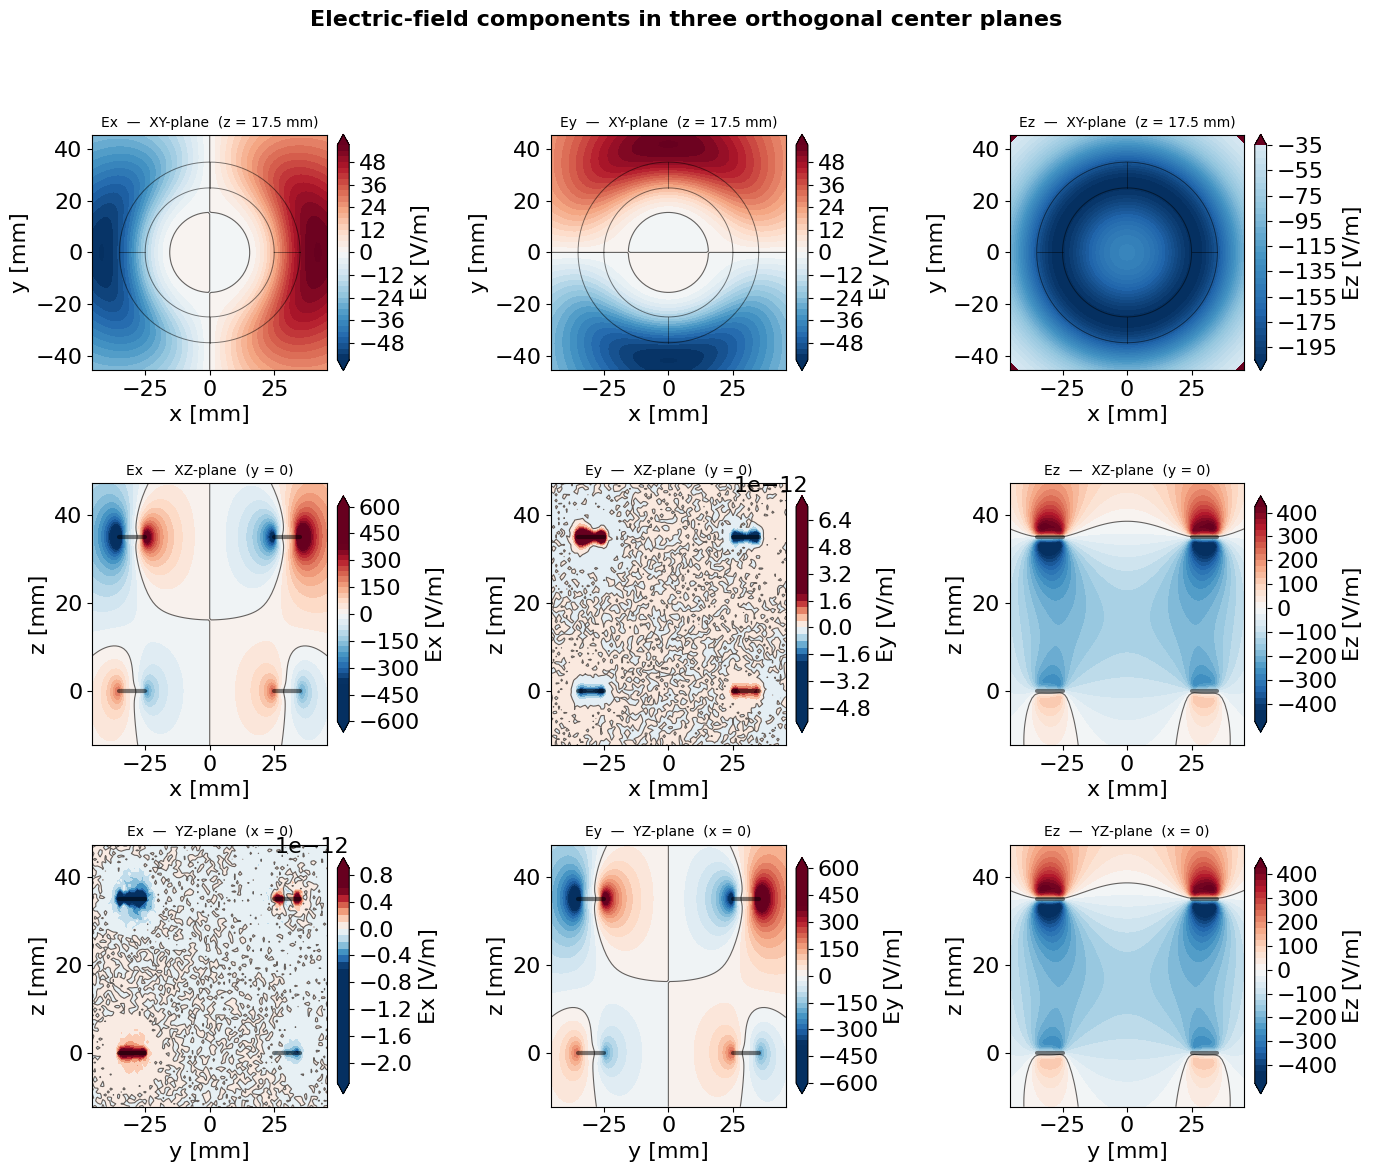

In [4]:

import matplotlib.pyplot as plt
from matplotlib import colors


# ----------------------------------------------------------------------
# Sample the FULL E-vector (Ex,Ey,Ez) on a plane through the center
# ----------------------------------------------------------------------
def sample_components(centers, areas, sigma, plane, n=90):
    """
    plane : 'xy' (z = d/2), 'xz' (y = 0), or 'yz' (x = 0).
    Returns coord1, coord2 (mm), Ex, Ey, Ez on the grid, plus axis labels.
    """
    zc  = d / 2.0
    sxy = Rout * 1.3                     # half-span in x/y
    z0, z1 = -0.35 * d, d + 0.35 * d     # z-range covering both rings

    if plane == "xy":
        u = np.linspace(-sxy, sxy, n)
        v = np.linspace(-sxy, sxy, n)
        U, V = np.meshgrid(u, v)
        pts = np.column_stack([U.ravel(), V.ravel(), np.full(U.size, zc)])
        lab = ("x [mm]", "y [mm]", f"XY-plane  (z = {zc*1e3:.1f} mm)")
    elif plane == "xz":
        u = np.linspace(-sxy, sxy, n)
        v = np.linspace(z0, z1, n)
        U, V = np.meshgrid(u, v)
        pts = np.column_stack([U.ravel(), np.zeros(U.size), V.ravel()])
        lab = ("x [mm]", "z [mm]", "XZ-plane  (y = 0)")
    else:  # 'yz'
        u = np.linspace(-sxy, sxy, n)
        v = np.linspace(z0, z1, n)
        U, V = np.meshgrid(u, v)
        pts = np.column_stack([np.zeros(U.size), U.ravel(), V.ravel()])
        lab = ("y [mm]", "z [mm]", "YZ-plane  (x = 0)")

    E = field_at(pts, centers, areas, sigma)
    Ex = E[:, 0].reshape(U.shape)
    Ey = E[:, 1].reshape(U.shape)
    Ez = E[:, 2].reshape(U.shape)
    return U * 1e3, V * 1e3, Ex, Ey, Ez, lab


# ----------------------------------------------------------------------
# Draw electrode outlines appropriate to each plane
# ----------------------------------------------------------------------
def overlay_geometry(ax, plane):
    if plane == "xy":
        ang = np.linspace(0, 2*np.pi, 200)
        for R in (Rin, Rout):
            ax.plot(R*np.cos(ang)*1e3, R*np.sin(ang)*1e3, "k", lw=.7, alpha=.5)
        for k in range(4):
            a = k*np.pi/2
            ax.plot([Rin*np.cos(a)*1e3, Rout*np.cos(a)*1e3],
                    [Rin*np.sin(a)*1e3, Rout*np.sin(a)*1e3],
                    "k", lw=.6, alpha=.5)
    else:
        # cross-section: rings appear as two short horizontal bars at z=0 and z=d
        for z in (0.0, d):
            for s in (+1, -1):
                ax.plot([s*Rin*1e3, s*Rout*1e3], [z*1e3, z*1e3],
                        "k", lw=3, alpha=.5, solid_capstyle="round")


# ======================================================================
# Main figure: 3 planes (rows) x 3 components (cols)
# ======================================================================
def field_component_figure(centers, areas, sigma, n=90):
    planes = ["xy", "xz", "yz"]
    comps  = ["Ex", "Ey", "Ez"]

    fig, axes = plt.subplots(3, 3, figsize=(14, 12))
    fig.suptitle("Electric-field components in three orthogonal center planes",
                 fontsize=16, weight="bold")

    for i, plane in enumerate(planes):
        U, V, Ex, Ey, Ez, lab = sample_components(centers, areas, sigma, plane, n)
        comp_data = {"Ex": Ex, "Ey": Ey, "Ez": Ez}

        for j, comp in enumerate(comps):
            ax = axes[i, j]
            data = comp_data[comp]

            # symmetric diverging scale centered on zero
            vmax = np.percentile(np.abs(data), 99)
            vmax = vmax if vmax > 0 else 1.0
            norm = colors.TwoSlopeNorm(vmin=-vmax, vcenter=0, vmax=vmax)

            cf = ax.contourf(U, V, data, levels=40, cmap="RdBu_r", norm=norm,
                             extend="both")
            ax.contour(U, V, data, levels=[0], colors="k",
                       linewidths=0.8, alpha=0.6)          # zero line
            overlay_geometry(ax, plane)

            cb = fig.colorbar(cf, ax=ax, fraction=0.046, pad=0.04)
            cb.set_label(f"{comp} [V/m]")

            ax.set_xlabel(lab[0])
            ax.set_ylabel(lab[1])
            ax.set_title(f"{comp}  —  {lab[2]}", fontsize=10)
            if plane == "xy":
                ax.set_aspect("equal")

    fig.tight_layout(rect=[0, 0, 1, 0.96])
    plt.savefig('ElectricDistrib.svg', format='svg')
    return fig


# ----------------------------------------------------------------------
if __name__ == "__main__":
    centers, areas, volts, seg_id = build_patches()
    sigma = solve_charges(centers, areas, volts)
    print(f"Solved {len(areas)} patches. Building field-component figure...")

    field_component_figure(centers, areas, sigma, n=90)
    plt.show()